Exploratory Data Analysis: Titanic Dataset

Student Name: [ Aber Hamoud Abd]  
Course: Big Data Analysis  

Introduction
This notebook presents an exploratory data analysis (EDA) of the Titanic dataset. The goal is to inspect passenger details, clean the data, visualize key distributions, and explore relationships between variables.

 Research Questions
1. How did survival rates differ by passenger class (Pclass)?
2. What was the impact of gender (Sex) on survival probability?
3. How does passenger age distribute, and is there a correlation with fare prices?

1. Import Required Libraries
In this cell, we import the essential Python libraries required for data manipulation, numerical computations, and data visualization.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

2. Load the Dataset
Here, we load the Titanic dataset from our project folder using a relative file path and display the first 5 rows to get an initial look at the structure and data fields.

In [3]:
df = pd.read_csv("dataset.csv")
display(df.head())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


3. Check Dataset Shape and Data Types
This step inspects the dimensions of the dataset (number of rows and columns) and checks the data types of each column along with non-null value counts to identify any potential missing data

In [4]:
print("Dataset Shape (Rows, Columns):", df.shape)
print("-" * 40)
df.info()

Dataset Shape (Rows, Columns): (418, 12)
----------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Survived     418 non-null    int64  
 2   Pclass       418 non-null    int64  
 3   Name         418 non-null    str    
 4   Sex          418 non-null    str    
 5   Age          332 non-null    float64
 6   SibSp        418 non-null    int64  
 7   Parch        418 non-null    int64  
 8   Ticket       418 non-null    str    
 9   Fare         417 non-null    float64
 10  Cabin        91 non-null     str    
 11  Embarked     418 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 56.1 KB


 4. Summary Statistics
In this cell, we generate descriptive statistics for all numerical columns (such as count, mean, standard deviation, min, and max values) to understand the central tendency and spread of the data

In [5]:
display(df.describe())

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,418.000000,418.000000,418.000000,332.000000,418.000000,418.000000,417.000000
mean,1100.500000,0.363636,2.265550,30.272590,0.447368,0.392344,35.627188
std,120.810458,0.481622,0.841838,14.181209,0.896760,0.981429,55.907576
min,892.000000,0.000000,1.000000,0.170000,0.000000,0.000000,0.000000
25%,996.250000,0.000000,1.000000,21.000000,0.000000,0.000000,7.895800
50%,1100.500000,0.000000,3.000000,27.000000,0.000000,0.000000,14.454200
75%,1204.750000,1.000000,3.000000,39.000000,1.000000,0.000000,31.500000
max,1309.000000,1.000000,3.000000,76.000000,8.000000,9.000000,512.329200


 5. Check for Missing Values
In this step, we check if there are any missing (null) values in our dataset across all columns to handle them properly

In [6]:
missing_values = df.isnull().sum()
print("--- Missing Values per Column ---")
print(missing_values[missing_values > 0])

--- Missing Values per Column ---
Age       86
Fare       1
Cabin    327
dtype: int64


6. Handle Missing Values
In this step, we address the missing values found in the dataset. For numerical columns like Age and Fare, we can fill the missing entries using statistical measures such as the median

In [7]:
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Fare'] = df['Fare'].fillna(df['Fare'].median())

# Verify that no missing values remain in Age and Fare
print("--- Missing Values After Cleaning ---")
print(df[['Age', 'Fare']].isnull().sum())

--- Missing Values After Cleaning ---
Age     0
Fare    0
dtype: int64


 7. Data Visualization and Analysis
In this section, we create visualizations to answer our research questions, such as exploring survival rates based on passenger class (Pclass) and gender (Sex)

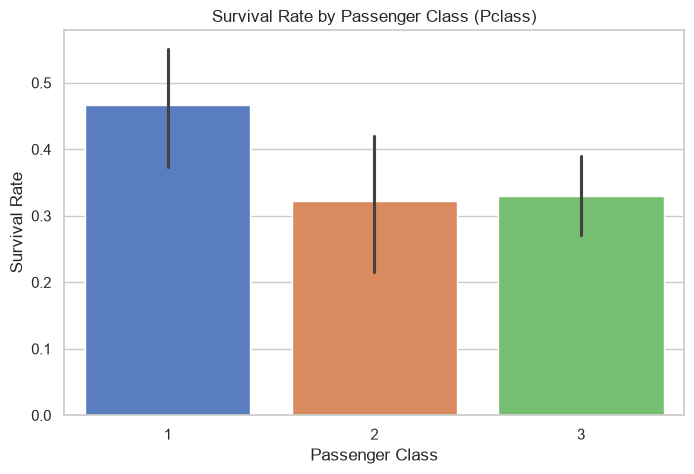

In [9]:
plt.figure(figsize=(8, 5))
sns.barplot(x='Pclass', y='Survived', data=df, palette='muted', hue='Pclass', legend=False)
plt.title('Survival Rate by Passenger Class (Pclass)')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.show()

8. Survival Rate by Gender (Sex)
In this section, we analyze and visualize how passenger gender affected survival probability during the Titanic disaster.

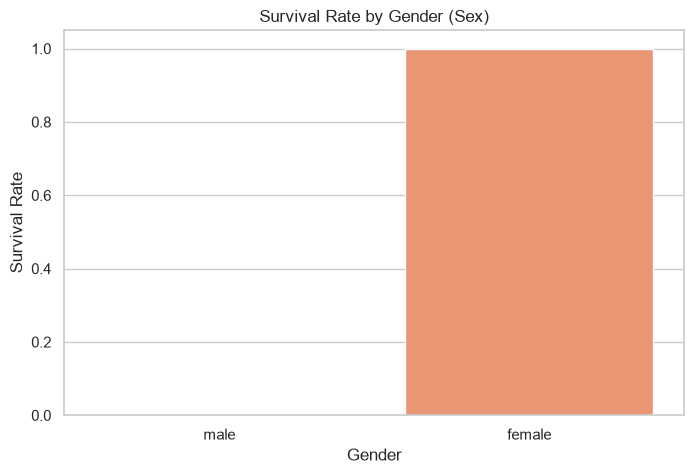

In [10]:
plt.figure(figsize=(8, 5))
sns.barplot(x='Sex', y='Survived', data=df, palette='Set2', hue='Sex', legend=False)
plt.title('Survival Rate by Gender (Sex)')
plt.xlabel('Gender')
plt.ylabel('Survival Rate')
plt.show()

9. Age Distribution of Passengers
In this final visualization, we examine the distribution of passenger ages on the Titanic using a histogram combined with a kernel density estimate (KDE).

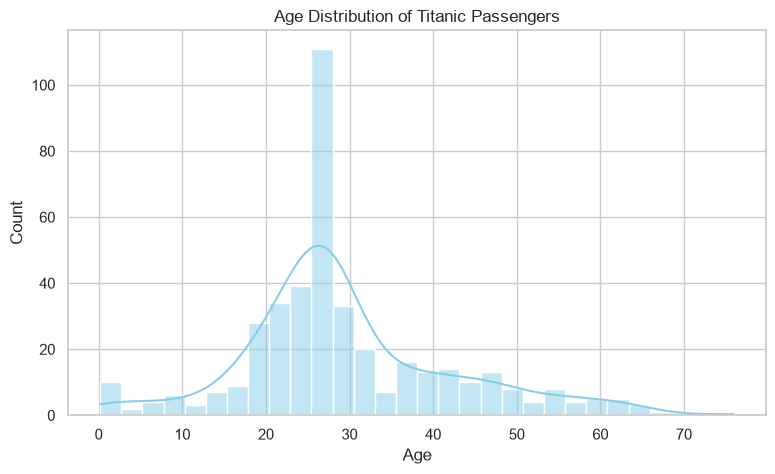

In [11]:
plt.figure(figsize=(9, 5))
sns.histplot(df['Age'], bins=30, kde=True, color='skyblue')
plt.title('Age Distribution of Titanic Passengers')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()